<a href="https://colab.research.google.com/github/JorgeLuisMadrid/Aprendizaje-Maquina-2026B/blob/main/L06_Red_Neuronal_BreastCancer.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Red Neuronal Densa: Diagnóstico de Cáncer de Mama
Dataset: `BreastCancerWisconsin.csv` — variable de interés: `diagnosis` (M = maligno, B = benigno).

## 1. Exploración del conjunto de datos y sus variables

Paso 1. Importamos la paquetería necesaria.

In [1]:
# Paquetería básica
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# TensorFlow y Keras
import tensorflow as tf
from tensorflow import keras

# Utilidades de Sklearn
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                              f1_score, confusion_matrix, classification_report,
                              roc_auc_score, roc_curve)

# Paleta de colores consistente para todas las gráficas
COLOR_TRAIN = '#2a78d6'   # azul
COLOR_VAL   = '#eb6834'   # naranja
COLOR_AUX   = '#1baf7a'   # aqua

np.random.seed(42)
tf.random.set_seed(42)

/Users/jorgeluismadrid/Documents/AM/Aprendizaje-Maquina-2026B/.venv/lib/python3.9/site-packages/urllib3/__init__.py:35: NotOpenSSLWarning: urllib3 v2 only supports OpenSSL 1.1.1+, currently the 'ssl' module is compiled with 'LibreSSL 2.8.3'. See: https://github.com/urllib3/urllib3/issues/3020
  warnings.warn(


Paso 2. Descargamos y cargamos el dataset.

In [2]:
!rm -f "BreastCancerWisconsin.csv"
!wget -q "https://raw.githubusercontent.com/JorgeLuisMadrid/Aprendizaje-Maquina-2026B/main/Datasets/BreastCancerWisconsin.csv" -O "BreastCancerWisconsin.csv"

dataset = pd.read_csv("BreastCancerWisconsin.csv")
dataset.head()

,id,diagnosis,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,...,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst,Unnamed: 32
0,842302,M,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,...,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,NaN
1,842517,M,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,...,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,NaN
2,84300903,M,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,...,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,NaN
3,84348301,M,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,...,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,NaN
4,84358402,M,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,...,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,NaN


Paso 3. Exploramos la estructura, los tipos de dato y las estadísticas descriptivas.

In [3]:
dataset.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 569 entries, 0 to 568
Data columns (total 33 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   id                       569 non-null    int64  
 1   diagnosis                569 non-null    object 
 2   radius_mean              569 non-null    float64
 3   texture_mean             569 non-null    float64
 4   perimeter_mean           569 non-null    float64
 5   area_mean                569 non-null    float64
 6   smoothness_mean          569 non-null    float64
 7   compactness_mean         569 non-null    float64
 8   concavity_mean           569 non-null    float64
 9   concave points_mean      569 non-null    float64
 10  symmetry_mean            569 non-null    float64
 11  fractal_dimension_mean   569 non-null    float64
 12  radius_se                569 non-null    float64
 13  texture_se               569 non-null    float64
 14  perimeter_se             5

In [4]:
dataset.describe()

,id,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,symmetry_mean,...,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst,Unnamed: 32
count,5.690000e+02,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,...,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,0.0
mean,3.037183e+07,14.127292,19.289649,91.969033,654.889104,0.096360,0.104341,0.088799,0.048919,0.181162,...,25.677223,107.261213,880.583128,0.132369,0.254265,0.272188,0.114606,0.290076,0.083946,NaN
std,1.250206e+08,3.524049,4.301036,24.298981,351.914129,0.014064,0.052813,0.079720,0.038803,0.027414,...,6.146258,33.602542,569.356993,0.022832,0.157336,0.208624,0.065732,0.061867,0.018061,NaN
min,8.670000e+03,6.981000,9.710000,43.790000,143.500000,0.052630,0.019380,0.000000,0.000000,0.106000,...,12.020000,50.410000,185.200000,0.071170,0.027290,0.000000,0.000000,0.156500,0.055040,NaN
25%,8.692180e+05,11.700000,16.170000,75.170000,420.300000,0.086370,0.064920,0.029560,0.020310,0.161900,...,21.080000,84.110000,515.300000,0.116600,0.147200,0.114500,0.064930,0.250400,0.071460,NaN
50%,9.060240e+05,13.370000,18.840000,86.240000,551.100000,0.095870,0.092630,0.061540,0.033500,0.179200,...,25.410000,97.660000,686.500000,0.131300,0.211900,0.226700,0.099930,0.282200,0.080040,NaN
75%,8.813129e+06,15.780000,21.800000,104.100000,782.700000,0.105300,0.130400,0.130700,0.074000,0.195700,...,29.720000,125.400000,1084.000000,0.146000,0.339100,0.382900,0.161400,0.317900,0.092080,NaN
max,9.113205e+08,28.110000,39.280000,188.500000,2501.000000,0.163400,0.345400,0.426800,0.201200,0.304000,...,49.540000,251.200000,4254.000000,0.222600,1.058000,1.252000,0.291000,0.663800,0.207500,NaN


Revisamos el balance de clases de la variable de interés.

diagnosis
B    357
M    212
Name: count, dtype: int64


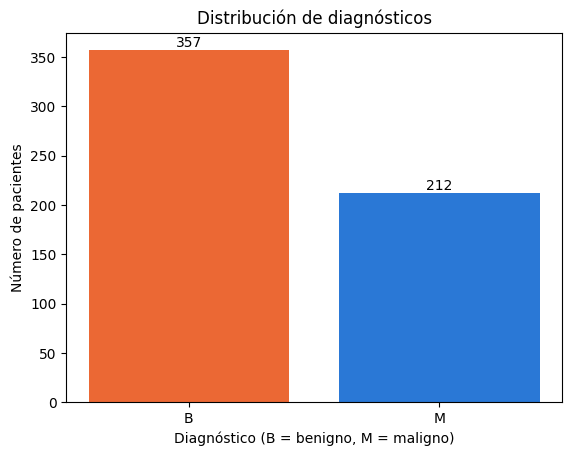

In [5]:
conteo = dataset['diagnosis'].value_counts()
print(conteo)

plt.figure()
plt.bar(conteo.index, conteo.values, color=[COLOR_VAL, COLOR_TRAIN])
plt.title('Distribución de diagnósticos')
plt.xlabel('Diagnóstico (B = benigno, M = maligno)')
plt.ylabel('Número de pacientes')
for i, v in enumerate(conteo.values):
    plt.text(i, v + 3, str(v), ha='center')
plt.show()

## 2. Limpieza del conjunto de datos y codificación de variables

Paso 4. Revisamos valores faltantes y columnas inútiles. La columna `id` es un identificador sin valor predictivo y `Unnamed: 32` proviene de una coma sobrante en el archivo original (queda completamente vacía), así que ambas se eliminan.

In [6]:
print('Valores faltantes por columna:')
print(dataset.isna().sum()[dataset.isna().sum() > 0])

dataset = dataset.drop(columns=['id', 'Unnamed: 32'])
dataset.head()

Valores faltantes por columna:
Unnamed: 32    569
dtype: int64


,diagnosis,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,symmetry_mean,...,radius_worst,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst
0,M,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,...,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,M,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,...,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,M,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,...,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758
3,M,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,...,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300
4,M,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,...,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678


Paso 5. Codificamos la variable de interés `diagnosis` como numérica (M = 1, B = 0). El resto de las variables ya son numéricas (mediciones de las células).

In [7]:
dataset['diagnosis'] = (dataset['diagnosis'] == 'M').astype(int)
print(dataset.dtypes.value_counts())
dataset.head()

float64    30
int64       1
Name: count, dtype: int64


,diagnosis,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,symmetry_mean,...,radius_worst,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst
0,1,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,...,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,...,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,1,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,...,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758
3,1,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,...,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300
4,1,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,...,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678


## 3. Variables de entrada y variable de salida

Paso 6. La variable de salida es `diagnosis`; el resto de las columnas son las variables de entrada.

In [8]:
x = np.asanyarray(dataset.drop(columns=['diagnosis']))
y = np.asanyarray(dataset[['diagnosis']])
print(x.shape)
print(y.shape)

(569, 30)
(569, 1)


## 4. Normalización y partición del conjunto de datos

Paso 7. Estandarizamos las variables de entrada y particionamos en entrenamiento (80%) y prueba (20%), manteniendo la proporción de clases con `stratify`.

In [9]:
scaler_x = StandardScaler()
x = scaler_x.fit_transform(x)

xtrain, xtest, ytrain, ytest = train_test_split(
    x, y, test_size=0.2, random_state=42, stratify=y)

print(xtrain.shape, xtest.shape)

(455, 30) (114, 30)


## 5. Diseño de la red neuronal

Paso 8. Diseñamos una red densa con dos capas ocultas (`relu`) y `Dropout` como regularización. Al ser un problema de clasificación binaria, la capa de salida tiene una neurona con activación `sigmoid` y usamos `binary_crossentropy` como función de pérdida.

In [10]:
def build_model(n_inputs, hidden1=64, hidden2=32, dropout=0.3, lr=1e-3):
    model = keras.Sequential()
    model.add(keras.layers.Dense(hidden1, activation='relu', input_shape=[n_inputs]))
    model.add(keras.layers.Dropout(dropout))
    model.add(keras.layers.Dense(hidden2, activation='relu'))
    model.add(keras.layers.Dense(1, activation='sigmoid'))

    model.compile(loss='binary_crossentropy',
                  optimizer=keras.optimizers.Adam(learning_rate=lr),
                  metrics=['accuracy', keras.metrics.AUC(name='auc')])
    return model

model = build_model(x.shape[1])
model.summary()

/Users/jorgeluismadrid/Documents/AM/Aprendizaje-Maquina-2026B/.venv/lib/python3.9/site-packages/keras/src/layers/core/dense.py:93: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 64)             │         1,984 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,097 (16.00 KB)

 Trainable params: 4,097 (16.00 KB)

 Non-trainable params: 0 (0.00 B)

## 6. Entrenamiento de la red y curvas de aprendizaje

Paso 9. Entrenamos la red con los hiperparámetros base.

In [11]:
history = model.fit(xtrain, ytrain,
                     batch_size=32, epochs=100,
                     validation_data=(xtest, ytest), verbose=0)
print('Última pérdida de validación:', history.history['val_loss'][-1])

Última pérdida de validación: 0.10820335894823074


Paso 10. Graficamos la evolución del entrenamiento a través de las épocas.

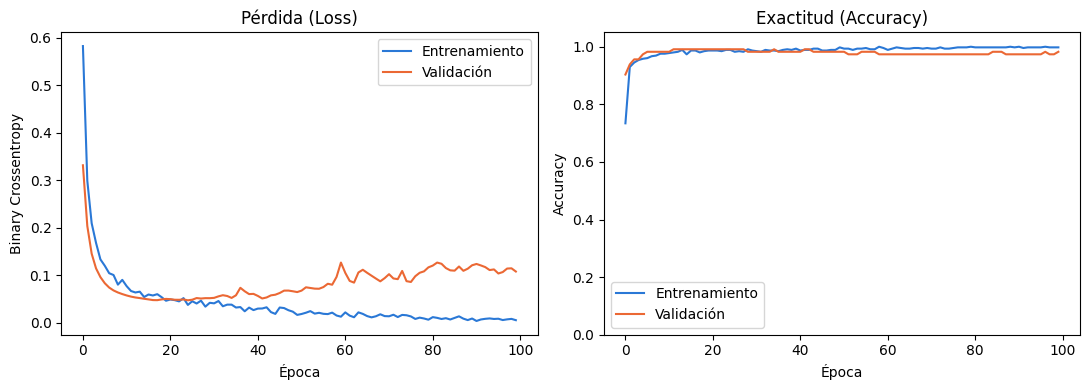

In [12]:
def plot_history(history):
    hist = pd.DataFrame(history.history)
    hist['epoch'] = history.epoch

    plt.figure(figsize=(11, 4))

    plt.subplot(1, 2, 1)
    plt.title('Pérdida (Loss)')
    plt.xlabel('Época')
    plt.ylabel('Binary Crossentropy')
    plt.plot(hist['epoch'], hist['loss'], color=COLOR_TRAIN, label='Entrenamiento')
    plt.plot(hist['epoch'], hist['val_loss'], color=COLOR_VAL, label='Validación')
    plt.legend()

    plt.subplot(1, 2, 2)
    plt.title('Exactitud (Accuracy)')
    plt.xlabel('Época')
    plt.ylabel('Accuracy')
    plt.plot(hist['epoch'], hist['accuracy'], color=COLOR_TRAIN, label='Entrenamiento')
    plt.plot(hist['epoch'], hist['val_accuracy'], color=COLOR_VAL, label='Validación')
    plt.ylim([0, 1.05])
    plt.legend()

    plt.tight_layout()
    plt.show()

plot_history(history)

## 7. Búsqueda de hiperparámetros

Paso 11. Probamos distintas combinaciones de número de neuronas, `dropout` y tasa de aprendizaje, entrenando cada combinación con `EarlyStopping` para evitar sobreajuste y comparando el desempeño sobre el conjunto de validación.

In [13]:
configs = [
    dict(hidden1=32, hidden2=16, dropout=0.2, lr=1e-3),
    dict(hidden1=64, hidden2=32, dropout=0.3, lr=1e-3),
    dict(hidden1=64, hidden2=32, dropout=0.4, lr=5e-4),
    dict(hidden1=128, hidden2=64, dropout=0.3, lr=1e-3),
    dict(hidden1=128, hidden2=64, dropout=0.5, lr=5e-4),
]

resultados = []
for cfg in configs:
    es = keras.callbacks.EarlyStopping(monitor='val_loss', mode='min', patience=10,
                                        restore_best_weights=True)
    m = build_model(x.shape[1], **cfg)
    h = m.fit(xtrain, ytrain, batch_size=32, epochs=150,
              validation_data=(xtest, ytest), verbose=0, callbacks=[es])
    val_loss = min(h.history['val_loss'])
    val_acc = max(h.history['val_accuracy'])
    resultados.append({**cfg, 'val_loss': val_loss, 'val_accuracy': val_acc,
                        'epochs_entrenadas': len(h.epoch)})

resultados_df = pd.DataFrame(resultados).sort_values('val_loss')
resultados_df

/Users/jorgeluismadrid/Documents/AM/Aprendizaje-Maquina-2026B/.venv/lib/python3.9/site-packages/keras/src/layers/core/dense.py:93: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


,hidden1,hidden2,dropout,lr,val_loss,val_accuracy,epochs_entrenadas
4,128,64,0.5,0.0005,0.053889,0.991228,41
3,128,64,0.3,0.0010,0.061582,0.982456,21
2,64,32,0.4,0.0005,0.062342,0.991228,43
1,64,32,0.3,0.0010,0.070270,0.982456,34
0,32,16,0.2,0.0010,0.091823,0.964912,25


Paso 12. Reentrenamos el modelo final con la mejor combinación de hiperparámetros encontrada.

Mejores hiperparámetros encontrados: {'hidden1': 128, 'hidden2': 64, 'dropout': np.float64(0.5), 'lr': np.float64(0.0005)}


/Users/jorgeluismadrid/Documents/AM/Aprendizaje-Maquina-2026B/.venv/lib/python3.9/site-packages/keras/src/layers/core/dense.py:93: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


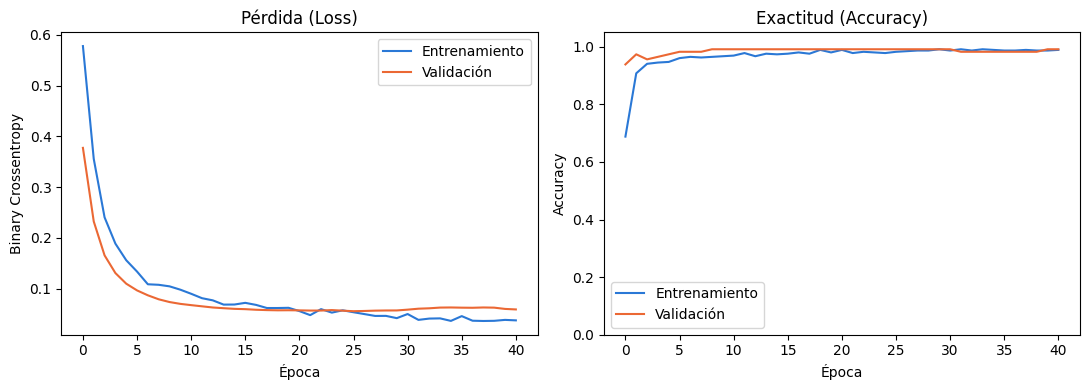

In [14]:
best_cfg = {k: resultados_df.iloc[0][k] for k in ['hidden1', 'hidden2', 'dropout', 'lr']}
best_cfg['hidden1'] = int(best_cfg['hidden1'])
best_cfg['hidden2'] = int(best_cfg['hidden2'])
print('Mejores hiperparámetros encontrados:', best_cfg)

es = keras.callbacks.EarlyStopping(monitor='val_loss', mode='min', patience=15,
                                    restore_best_weights=True)
final_model = build_model(x.shape[1], **best_cfg)
history_final = final_model.fit(xtrain, ytrain, batch_size=32, epochs=200,
                                 validation_data=(xtest, ytest), verbose=0,
                                 callbacks=[es])
plot_history(history_final)

## 8. Métricas de desempeño

Paso 13. Calculamos las métricas de clasificación sobre el conjunto de prueba.

In [15]:
y_prob = final_model.predict(xtest, verbose=0).ravel()
y_pred = (y_prob >= 0.5).astype(int)

print('Accuracy :', accuracy_score(ytest, y_pred))
print('Precision:', precision_score(ytest, y_pred))
print('Recall   :', recall_score(ytest, y_pred))
print('F1-score :', f1_score(ytest, y_pred))
print('ROC-AUC  :', roc_auc_score(ytest, y_prob))
print()
print(classification_report(ytest, y_pred, target_names=['Benigno', 'Maligno']))

Accuracy : 0.9912280701754386
Precision: 1.0
Recall   : 0.9761904761904762
F1-score : 0.9879518072289156
ROC-AUC  : 0.9973544973544973

              precision    recall  f1-score   support

     Benigno       0.99      1.00      0.99        72
     Maligno       1.00      0.98      0.99        42

    accuracy                           0.99       114
   macro avg       0.99      0.99      0.99       114
weighted avg       0.99      0.99      0.99       114



Paso 14. Visualizamos la matriz de confusión y la curva ROC.

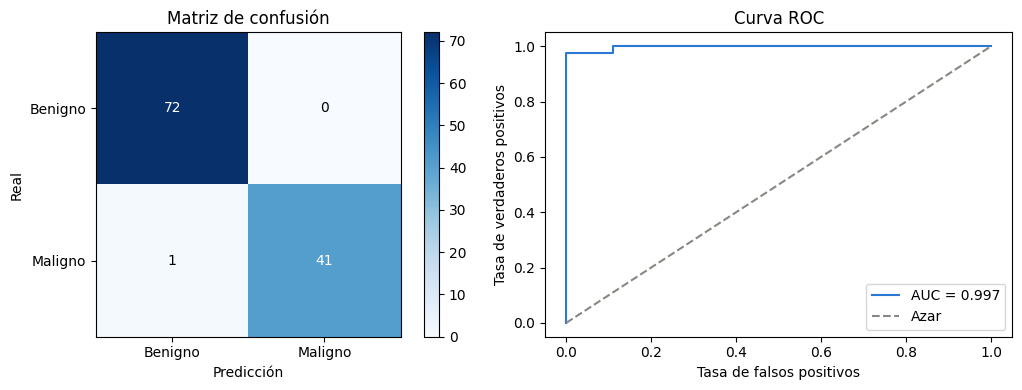

In [16]:
cm = confusion_matrix(ytest, y_pred)
fpr, tpr, _ = roc_curve(ytest, y_prob)

plt.figure(figsize=(11, 4))

plt.subplot(1, 2, 1)
plt.imshow(cm, cmap='Blues')
plt.title('Matriz de confusión')
plt.xlabel('Predicción')
plt.ylabel('Real')
plt.xticks([0, 1], ['Benigno', 'Maligno'])
plt.yticks([0, 1], ['Benigno', 'Maligno'])
for i in range(2):
    for j in range(2):
        plt.text(j, i, cm[i, j], ha='center', va='center',
                  color='white' if cm[i, j] > cm.max() / 2 else 'black')
plt.colorbar()

plt.subplot(1, 2, 2)
plt.plot(fpr, tpr, color=COLOR_TRAIN, label=f'AUC = {roc_auc_score(ytest, y_prob):.3f}')
plt.plot([0, 1], [0, 1], '--', color='#898781', label='Azar')
plt.title('Curva ROC')
plt.xlabel('Tasa de falsos positivos')
plt.ylabel('Tasa de verdaderos positivos')
plt.legend()

plt.tight_layout()
plt.show()